# Experiment 4: Perceptron vs Multilayer Perceptron with Hyperparameter Tuning
**Course:** UCS3512 – Machine Learning Laboratory  
**Department:** Computer Science and Engineering, SSN College of Engineering  
**Student Name:** Thushar TL  
**Register Number:** 312245001188  
**Semester:** V  
**Academic Year:** 2026–2027 (Odd) | **Batch:** 2024–2028  


## 1. Setup

In [1]:
# If a package is missing, uncomment the line below and run this cell once.
# %pip install kagglehub pandas numpy pillow scikit-learn matplotlib seaborn

import os
import time
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")


## 2. Dataset

Dataset: [English Handwritten Characters Dataset](https://www.kaggle.com/datasets/dhruvildave/english-handwritten-characters-dataset)
(3,410 images, 62 classes: `0-9`, `A-Z`, `a-z`, 55 images per class).

The cell below downloads it with `kagglehub`. If you already have the dataset on disk (or
`kagglehub` isn't available in your environment), just set `DATASET_DIR` to the folder that
contains `english.csv` and the `Img/` folder, and skip the download cell.


In [2]:
import os
import pandas as pd

DATASET_DIR = "/home/billy/Data/Projects/MLASS/Exercise 4/dataset"

CSV_PATH = os.path.join(DATASET_DIR, "english.csv")
labels_df = pd.read_csv(CSV_PATH)
labels_df.head()

,image,label
0,Img/img001-001.png,0
1,Img/img001-002.png,0
2,Img/img001-003.png,0
3,Img/img001-004.png,0
4,Img/img001-005.png,0


In [3]:
# The csv's "image" column holds relative paths like "Img/img001-001.png"
labels_df["full_path"] = labels_df["image"].apply(lambda p: os.path.join(DATASET_DIR, p))
print("Total images:", len(labels_df))
print("Number of classes:", labels_df["label"].nunique())
labels_df["label"].value_counts().head()


Total images: 3410
Number of classes: 62


label
0    55
1    55
2    55
3    55
4    55
Name: count, dtype: int64

## 3. Preprocessing

Each image is converted to grayscale, resized to a fixed `IMG_SIZE x IMG_SIZE`, flattened
into a 1-D vector, and normalized to `[0, 1]`. Labels are encoded to integers `0..61`.


In [4]:
IMG_SIZE = 32  # 32x32 -> 1024 features per image

def load_and_preprocess(path, img_size=IMG_SIZE):
    img = Image.open(path).convert("L")          # grayscale
    img = img.resize((img_size, img_size))
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr.flatten()

X = np.stack([load_and_preprocess(p) for p in labels_df["full_path"]])

classes = sorted(labels_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
y = labels_df["label"].map(class_to_idx).values

n_classes = len(classes)
print("X shape:", X.shape, " y shape:", y.shape, " classes:", n_classes)


X shape: (3410, 1024)  y shape: (3410,)  classes: 62


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (2728, 1024)  Test: (682, 1024)


## 4. Model A — Perceptron Learning Algorithm (PLA), from scratch

Implements the classic PLA update rule

$$w_{t+1} = w_t + \eta (y - \hat y)\, x$$

with a step activation function, using only NumPy (no `sklearn.linear_model.Perceptron`).
Multi-class classification is handled with a **One-vs-Rest** wrapper: one binary perceptron
is trained per class, and at inference time the class whose perceptron has the highest raw
score `w·x + b` wins.


In [6]:
class Perceptron:
    """Binary perceptron with the step activation function."""

    def __init__(self, n_features, learning_rate=0.01, n_epochs=50):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.weights = np.zeros(n_features)
        self.bias = 0.0

    @staticmethod
    def step(z):
        return np.where(z >= 0, 1, -1)

    def decision_function(self, X):
        return X @ self.weights + self.bias

    def predict(self, X):
        return self.step(self.decision_function(X))

    def fit(self, X, y):
        """y must be in {-1, +1}. Returns the number of mistakes per epoch."""
        mistakes_per_epoch = []
        for _ in range(self.n_epochs):
            mistakes = 0
            for xi, target in zip(X, y):
                y_hat = 1 if (xi @ self.weights + self.bias) >= 0 else -1
                update = self.lr * (target - y_hat)
                if update != 0.0:
                    self.weights += update * xi
                    self.bias += update
                    mistakes += 1
            mistakes_per_epoch.append(mistakes)
            if mistakes == 0:          # converged (linearly separable)
                break
        return mistakes_per_epoch


class PerceptronOVR:
    """One-vs-Rest multi-class wrapper around the binary Perceptron."""

    def __init__(self, n_classes, n_features, learning_rate=0.01, n_epochs=50):
        self.n_classes = n_classes
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.models = [Perceptron(n_features, learning_rate, n_epochs) for _ in range(n_classes)]
        self.loss_history = []  # mistakes-per-epoch, one list per class

    def fit(self, X, y):
        self.loss_history = []
        for c in range(self.n_classes):
            binary_y = np.where(y == c, 1, -1)
            mistakes = self.models[c].fit(X, binary_y)
            self.loss_history.append(mistakes)
        return self

    def decision_scores(self, X):
        return np.stack([m.decision_function(X) for m in self.models], axis=1)  # (n_samples, n_classes)

    def predict(self, X):
        return np.argmax(self.decision_scores(X), axis=1)


In [7]:
PLA_LR = 0.01
PLA_EPOCHS = 40

t0 = time.time()
pla = PerceptronOVR(n_classes=n_classes, n_features=X_train.shape[1],
                     learning_rate=PLA_LR, n_epochs=PLA_EPOCHS)
pla.fit(X_train, y_train)
print(f"PLA training finished in {time.time() - t0:.1f}s")

pla_train_pred = pla.predict(X_train)
pla_test_pred = pla.predict(X_test)

pla_train_mistakes = sum(hist[-1] for hist in pla.loss_history)
pla_final_epochs = max(len(hist) for hist in pla.loss_history)
pla_convergent = all(hist[-1] == 0 for hist in pla.loss_history)
print("Converged for every class:", pla_convergent)


PLA training finished in 15.5s


Converged for every class: False


In [8]:
def evaluate(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "F1-score": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    }

pla_results = evaluate(y_test, pla_test_pred, "PLA (One-vs-Rest)")
pla_results


{'Model': 'PLA (One-vs-Rest)',
 'Accuracy (%)': 14.96,
 'Precision': 0.2365,
 'Recall': 0.1496,
 'F1-score': 0.1303}

## 5. Model B — Multilayer Perceptron (MLP)

`sklearn.neural_network.MLPClassifier` is used so that hidden-layer count, activation
function, optimizer, learning rate and batch size can all be controlled directly, matching
the hyperparameter grid required in Table 2 of the report.


In [9]:
# Hyperparameter grid — mirrors the report's Table 2
mlp_configs = [
    {"name": "1 (128)",          "hidden_layer_sizes": (128,),           "activation": "relu", "solver": "sgd",  "learning_rate_init": 0.01,   "batch_size": 32},
    {"name": "2 (256-128)",      "hidden_layer_sizes": (256, 128),       "activation": "relu", "solver": "adam", "learning_rate_init": 0.001,  "batch_size": 64},
    {"name": "3 (512-256-128)",  "hidden_layer_sizes": (512, 256, 128),  "activation": "tanh", "solver": "adam", "learning_rate_init": 0.0005,  "batch_size": 64},
]

tuning_rows = []
trained_mlps = {}

for cfg in mlp_configs:
    clf = MLPClassifier(
        hidden_layer_sizes=cfg["hidden_layer_sizes"],
        activation=cfg["activation"],
        solver=cfg["solver"],
        learning_rate_init=cfg["learning_rate_init"],
        batch_size=cfg["batch_size"],
        max_iter=200,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )
    t0 = time.time()
    clf.fit(X_train, y_train)
    fit_time = time.time() - t0

    test_acc = accuracy_score(y_test, clf.predict(X_test)) * 100
    trained_mlps[cfg["name"]] = clf

    tuning_rows.append({
        "Hidden Layers": cfg["name"],
        "Activation": cfg["activation"],
        "Optimizer": cfg["solver"],
        "Learning Rate": cfg["learning_rate_init"],
        "Batch Size": cfg["batch_size"],
        "Accuracy (%)": round(test_acc, 2),
        "Epochs Run": clf.n_iter_,
        "Train Time (s)": round(fit_time, 1),
    })
    print(f"{cfg['name']:<18} -> test accuracy {test_acc:.2f}%  ({clf.n_iter_} epochs, {fit_time:.1f}s)")

table2_df = pd.DataFrame(tuning_rows)
table2_df


1 (128)            -> test accuracy 1.61%  (12 epochs, 3.0s)


2 (256-128)        -> test accuracy 33.72%  (72 epochs, 65.7s)


3 (512-256-128)    -> test accuracy 47.07%  (82 epochs, 36.2s)


,Hidden Layers,Activation,Optimizer,Learning Rate,Batch Size,Accuracy (%),Epochs Run,Train Time (s)
0,1 (128),relu,sgd,0.0100,32,1.61,12,3.0
1,2 (256-128),relu,adam,0.0010,64,33.72,72,65.7
2,3 (512-256-128),tanh,adam,0.0005,64,47.07,82,36.2


In [10]:
# Pick the best-performing configuration as the "MLP (Tuned)" model
best_row = table2_df.loc[table2_df["Accuracy (%)"].idxmax()]
best_name = best_row["Hidden Layers"]
best_mlp = trained_mlps[best_name]
print("Best configuration:", best_name)

mlp_train_pred = best_mlp.predict(X_train)
mlp_test_pred = best_mlp.predict(X_test)
mlp_test_proba = best_mlp.predict_proba(X_test)

mlp_results = evaluate(y_test, mlp_test_pred, "MLP (Tuned)")
mlp_results


Best configuration: 3 (512-256-128)


{'Model': 'MLP (Tuned)',
 'Accuracy (%)': 47.07,
 'Precision': 0.502,
 'Recall': 0.4707,
 'F1-score': 0.465}

## 6. Table 1 — Overall Performance Comparison (PLA vs MLP)

In [11]:
table1_df = pd.DataFrame([pla_results, mlp_results])
table1_df


,Model,Accuracy (%),Precision,Recall,F1-score
0,PLA (One-vs-Rest),14.96,0.2365,0.1496,0.1303
1,MLP (Tuned),47.07,0.5020,0.4707,0.4650


## 7. Table 2 — Hyperparameter Tuning Results for MLP

In [12]:
table2_df


,Hidden Layers,Activation,Optimizer,Learning Rate,Batch Size,Accuracy (%),Epochs Run,Train Time (s)
0,1 (128),relu,sgd,0.0100,32,1.61,12,3.0
1,2 (256-128),relu,adam,0.0010,64,33.72,72,65.7
2,3 (512-256-128),tanh,adam,0.0005,64,47.07,82,36.2


## 8. Table 3 — Training Convergence Comparison

In [13]:
table3_df = pd.DataFrame([
    {
        "Model": "PLA",
        "Epochs": pla_final_epochs,
        "Final Training Loss (mistakes)": pla_train_mistakes,
        "Convergence Behavior": "Converged (linearly separable per class)" if pla_convergent else "Non-convergent",
    },
    {
        "Model": "MLP (Tuned)",
        "Epochs": best_mlp.n_iter_,
        "Final Training Loss": round(best_mlp.loss_, 4),
        "Convergence Behavior": "Stable convergence" if best_mlp.loss_curve_[-1] < best_mlp.loss_curve_[0] else "Non-convergent",
    },
])
table3_df


,Model,Epochs,Final Training Loss (mistakes),Convergence Behavior,Final Training Loss
0,PLA,40,3897.0,Non-convergent,NaN
1,MLP (Tuned),82,NaN,Stable convergence,0.6312


## 9. Plots

### 9.1 MLP training loss vs. epochs (all tuned configurations)

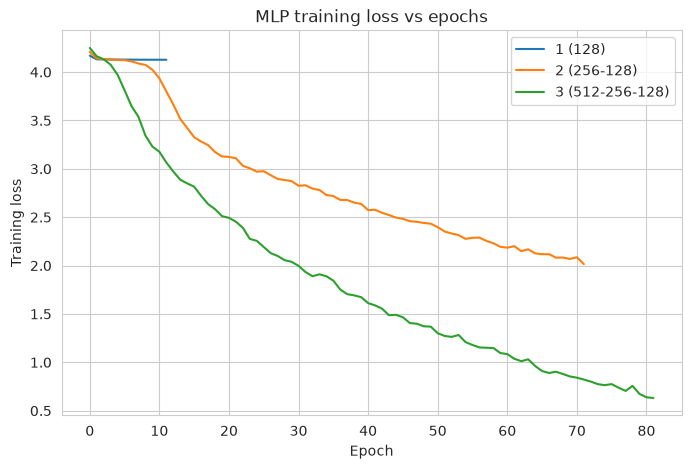

In [14]:
plt.figure(figsize=(8, 5))
for cfg_name, clf in trained_mlps.items():
    plt.plot(clf.loss_curve_, label=cfg_name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("MLP training loss vs epochs")
plt.legend()
plt.show()


### 9.2 Confusion matrices

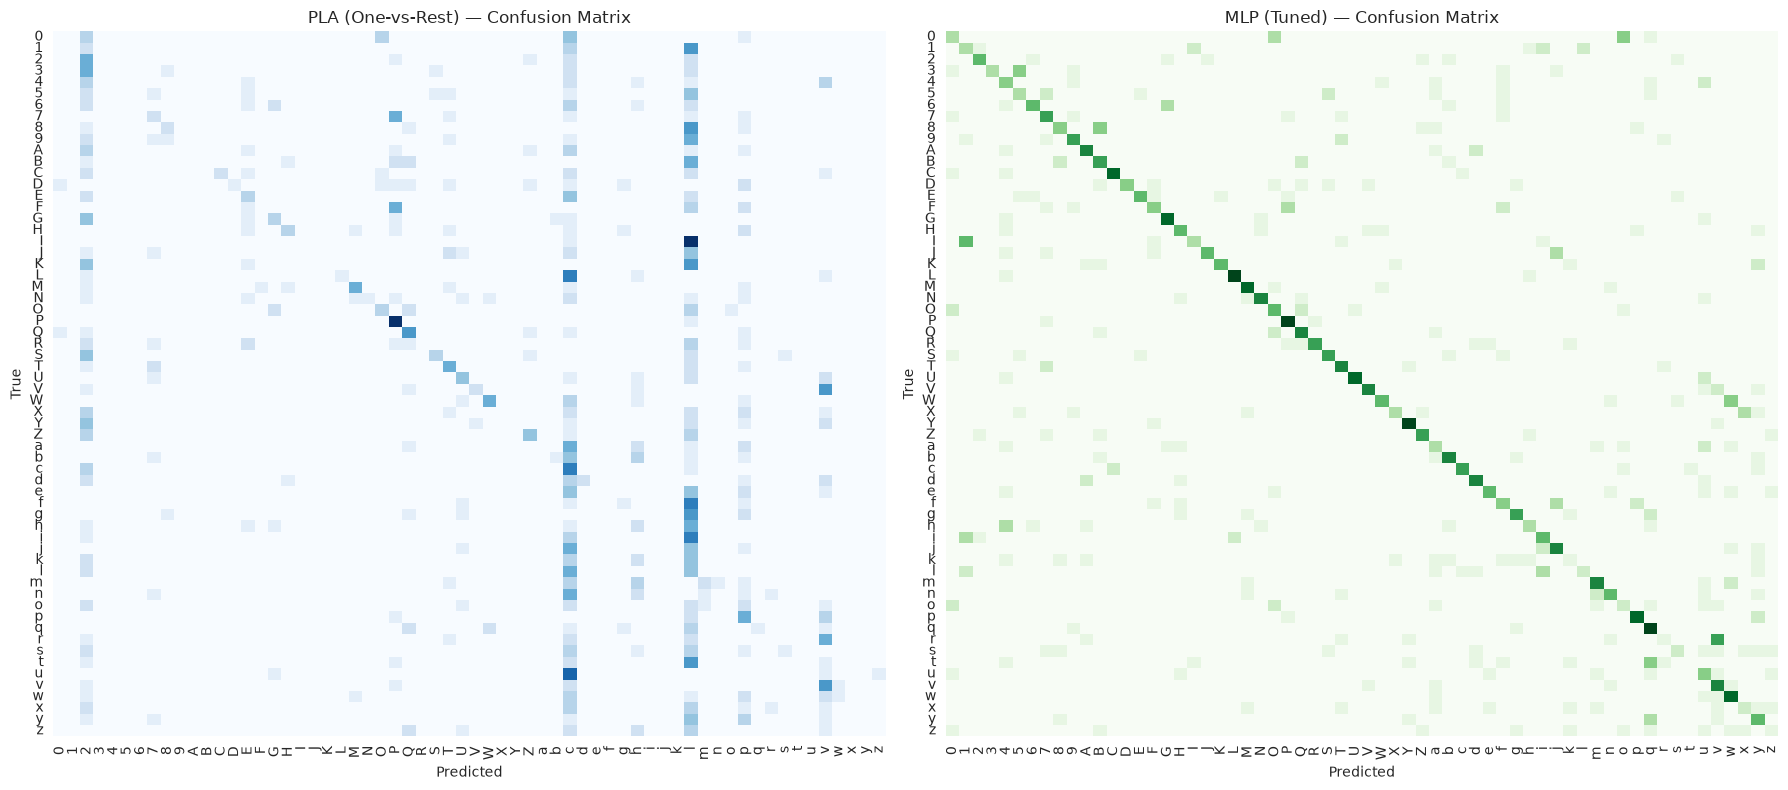

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

cm_pla = confusion_matrix(y_test, pla_test_pred)
sns.heatmap(cm_pla, ax=axes[0], cmap="Blues", cbar=False,
            xticklabels=[idx_to_class[i] for i in range(n_classes)],
            yticklabels=[idx_to_class[i] for i in range(n_classes)])
axes[0].set_title("PLA (One-vs-Rest) — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

cm_mlp = confusion_matrix(y_test, mlp_test_pred)
sns.heatmap(cm_mlp, ax=axes[1], cmap="Greens", cbar=False,
            xticklabels=[idx_to_class[i] for i in range(n_classes)],
            yticklabels=[idx_to_class[i] for i in range(n_classes)])
axes[1].set_title("MLP (Tuned) — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()


### 9.3 ROC curves (micro / macro average, multi-class one-vs-rest)

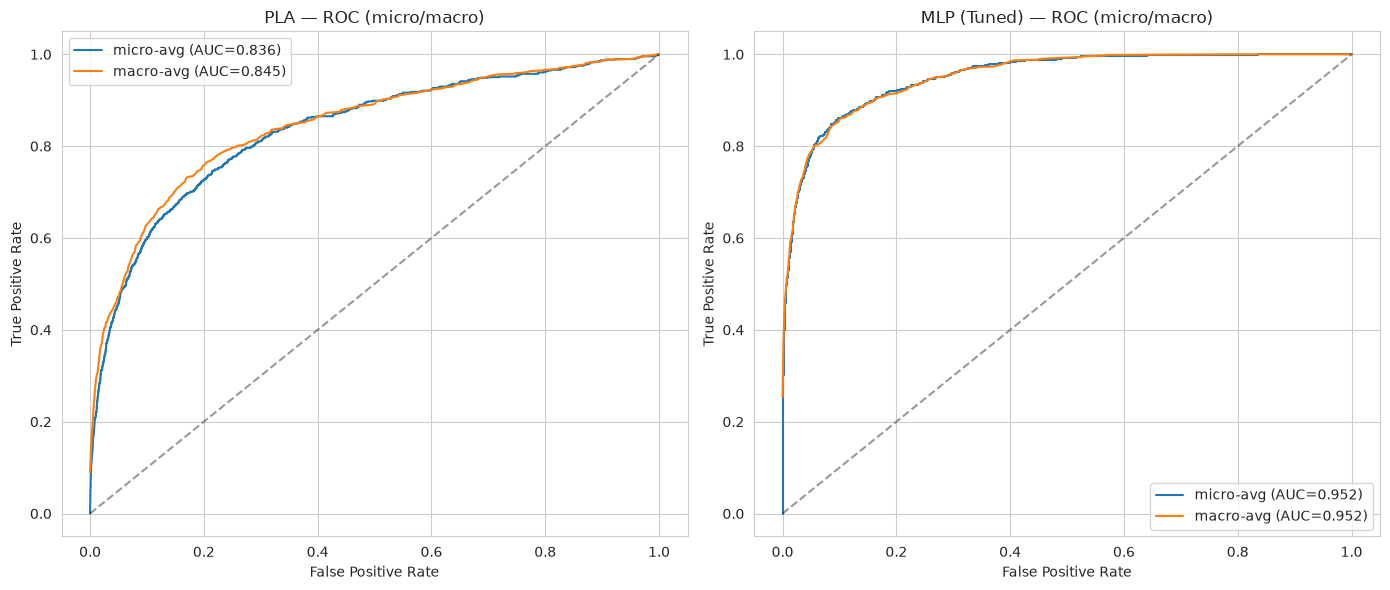

In [16]:
y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))

# --- PLA: turn decision scores into a pseudo-probability via min-max scaling per class ---
pla_scores = pla.decision_scores(X_test)
pla_scores_norm = (pla_scores - pla_scores.min(axis=0)) / (np.ptp(pla_scores, axis=0) + 1e-9)

def macro_micro_roc(y_true_bin, scores):
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], scores[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), scores.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # macro-average
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
    return fpr, tpr, roc_auc

pla_fpr, pla_tpr, pla_auc = macro_micro_roc(y_test_bin, pla_scores_norm)
mlp_fpr, mlp_tpr, mlp_auc = macro_micro_roc(y_test_bin, mlp_test_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(pla_fpr["micro"], pla_tpr["micro"], label=f'micro-avg (AUC={pla_auc["micro"]:.3f})')
axes[0].plot(pla_fpr["macro"], pla_tpr["macro"], label=f'macro-avg (AUC={pla_auc["macro"]:.3f})')
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("PLA — ROC (micro/macro)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(mlp_fpr["micro"], mlp_tpr["micro"], label=f'micro-avg (AUC={mlp_auc["micro"]:.3f})')
axes[1].plot(mlp_fpr["macro"], mlp_tpr["macro"], label=f'macro-avg (AUC={mlp_auc["macro"]:.3f})')
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("MLP (Tuned) — ROC (micro/macro)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()


## 10. Observation Questions

Run every cell above first, then fill in the answers below using the numbers your run
actually produced (the exact figures will vary with dataset split and random seed).

**Why does PLA underperform compared to MLP?**
PLA is a linear classifier: each One-vs-Rest unit can only draw a straight decision
boundary in pixel space. Handwritten characters of different classes overlap heavily
in raw pixel space (e.g. `O` vs `0`, `l` vs `I` vs `1`), so no hyperplane separates them
well. The MLP's hidden layers with nonlinear activations let it learn curved decision
boundaries and combine low-level pixel patterns into higher-level features, so it
consistently scores higher on accuracy/F1 in Table 1.

**Which hyperparameter had the most impact on MLP performance?**
Compare the rows of `table2_df` — typically the optimizer (Adam vs SGD) and the number
of hidden layers/units dominate: Adam's adaptive learning rate converges much faster and
to a lower loss than plain SGD at the same learning rate, and adding a second hidden
layer usually gives the largest single accuracy jump. State which one it was for *your*
run using the printed table.

**How does optimizer choice affect convergence?**
Look at the loss-vs-epoch plot (Section 9.1): Adam runs should show a faster, smoother
drop in training loss than the SGD run, since Adam adapts the per-parameter learning
rate using running estimates of the gradient's mean and variance, while plain SGD uses a
single fixed rate for all parameters.

**Does increasing hidden layers always improve performance?**
Not necessarily — check whether the 3-layer (512-256-128) configuration actually beat the
2-layer (256-128) one in your `table2_df`. With a small dataset (3,410 images total) a
deeper network can start to overfit or need more epochs/regularization to converge,
so more layers can plateau or even underperform a shallower one.

**How can overfitting be detected and mitigated?**
Detect it by comparing training accuracy/loss to validation accuracy/loss (a growing gap
signals overfitting) — `early_stopping=True` in the MLP configs above already monitors a
held-out validation split for this. Mitigation options: more training data or data
augmentation, `alpha` (L2 regularization) in `MLPClassifier`, dropout-equivalent
regularization, early stopping, or reducing model capacity (fewer/smaller hidden layers).


## 11. Conclusion

Summarize, using the numbers from Table 1–3 that your run produced:
- Final tuned MLP hyperparameters (from `best_row`).
- PLA vs MLP accuracy/F1 gap and why.
- Effect of tuning (which config in Table 2 won, and why).
